Part 4

Technique 1 Reweighing (pre-processing)

Load Required Libraries and Data

In [ ]:
# Install required libraries
!pip install aif360 fairlearn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax
import torch
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Load the original training and evaluation data
train_df = pd.read_csv("/content/drive/MyDrive/train_subset_100k.csv", encoding="latin1")
eval_df = pd.read_csv("/content/drive/MyDrive/eval_subset_20k.csv", encoding="latin1")

# Load the tokenizer and model
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding
from datasets import Dataset

tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

def tokenize_function(batch):
    return tokenizer(
        batch["comment_text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# Create baseline predictions for comparison
def get_model_predictions(model, dataset):
    trainer_temp = Trainer(model=model, args=TrainingArguments(output_dir="./temp", report_to="none"))
    preds = trainer_temp.predict(dataset)
    probs = softmax(preds.predictions, axis=1)[:, 1]
    return probs, preds.label_ids

print("Data loaded successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.7/259.7 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.6/251.6 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 38.0 MB/s eta 0:00:00


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Data loaded successfully!


In [ ]:
def compute_fairness_metrics(df, y_true, y_pred, probs=None):
    """Compute fairness metrics for a given cohort"""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    TPR = tp / (tp + fn) if (tp + fn) > 0 else 0
    FPR = fp / (fp + tn) if (fp + tn) > 0 else 0
    FNR = fn / (fn + tp) if (fn + tp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    return {
        "TPR": TPR,
        "FPR": FPR,
        "FNR": FNR,
        "Precision": precision,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

def evaluate_model(model, eval_dataset, eval_df, threshold=0.5):
    """Evaluate model and compute all metrics"""
    # Get predictions
    trainer_temp = Trainer(model=model, args=TrainingArguments(output_dir="./temp", report_to="none"))
    preds = trainer_temp.predict(eval_dataset)
    probs = softmax(preds.predictions, axis=1)[:, 1]
    y_pred = (probs >= threshold).astype(int)
    y_true = preds.label_ids

    # Overall metrics
    overall_f1 = f1_score(y_true, y_pred, average="macro")
    overall_acc = accuracy_score(y_true, y_pred)
    overall_auc = roc_auc_score(y_true, probs)

    # Cohort definitions
    high_black = eval_df[eval_df["black"] >= 0.5]
    reference = eval_df[(eval_df["black"] < 0.1) & (eval_df["white"] >= 0.5)]

    # Get indices for cohorts
    hb_indices = high_black.index.tolist()
    ref_indices = reference.index.tolist()

    # Compute metrics for each cohort
    hb_metrics = compute_fairness_metrics(high_black, y_true[hb_indices], y_pred[hb_indices])
    ref_metrics = compute_fairness_metrics(reference, y_true[ref_indices], y_pred[ref_indices])

    # Disparate Impact and differences
    disparate_impact = hb_metrics["FPR"] / ref_metrics["FPR"] if ref_metrics["FPR"] > 0 else float('inf')
    spd = hb_metrics["FPR"] - ref_metrics["FPR"]  # Statistical Parity Difference (using FPR)
    eod = hb_metrics["TPR"] - ref_metrics["TPR"]  # Equal Opportunity Difference

    return {
        "overall_f1": overall_f1,
        "overall_auc": overall_auc,
        "overall_acc": overall_acc,
        "hb_fpr": hb_metrics["FPR"],
        "hb_tpr": hb_metrics["TPR"],
        "ref_fpr": ref_metrics["FPR"],
        "ref_tpr": ref_metrics["TPR"],
        "spd": spd,
        "eod": eod,
        "disparate_impact": disparate_impact
    }

print("Helper functions defined!")

Helper functions defined!


In [ ]:
# Prepare training dataset
train_dataset = Dataset.from_pandas(train_df)
train_dataset = train_dataset.map(tokenize_function, batched=True)
train_dataset = train_dataset.rename_column("label", "labels")
train_dataset = train_dataset.remove_columns([col for col in train_dataset.column_names if col not in ["input_ids", "attention_mask", "labels"]])

# Prepare evaluation dataset
eval_dataset = Dataset.from_pandas(eval_df)
eval_dataset = eval_dataset.map(tokenize_function, batched=True)
eval_dataset = eval_dataset.rename_column("label", "labels")
eval_dataset = eval_dataset.remove_columns([col for col in eval_dataset.column_names if col not in ["input_ids", "attention_mask", "labels"]])

print(f"Train dataset size: {len(train_dataset)}")
print(f"Eval dataset size: {len(eval_dataset)}")

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Train dataset size: 100000
Eval dataset size: 20000


In [ ]:
# Load the original trained model
from transformers import DistilBertForSequenceClassification

baseline_model = DistilBertForSequenceClassification.from_pretrained("/content/drive/MyDrive/distilbert_jigsaw_model")
baseline_model.to("cuda" if torch.cuda.is_available() else "cpu")

# Evaluate baseline
print("Evaluating baseline model...")
baseline_results = evaluate_model(baseline_model, eval_dataset, eval_df, threshold=0.6)

print("\n=== BASELINE RESULTS ===")
print(f"Overall F1: {baseline_results['overall_f1']:.4f}")
print(f"High-Black FPR: {baseline_results['hb_fpr']:.4f}")
print(f"Reference FPR: {baseline_results['ref_fpr']:.4f}")
print(f"Statistical Parity Difference (FPR diff): {baseline_results['spd']:.4f}")
print(f"Equal Opportunity Difference (TPR diff): {baseline_results['eod']:.4f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Evaluating baseline model...



=== BASELINE RESULTS ===
Overall F1: 0.7866
High-Black FPR: 0.0280
Reference FPR: 0.0345
Statistical Parity Difference (FPR diff): -0.0064
Equal Opportunity Difference (TPR diff): 0.0911


In [ ]:
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.preprocessing import Reweighing
import warnings
warnings.filterwarnings('ignore')

# Prepare data for AIF360
# Create protected attribute: 1 for high-black, 0 for reference (others as -1 for training)
train_df_aif = train_df.copy()
train_df_aif["protected"] = 0  # default
train_df_aif.loc[train_df_aif["black"] >= 0.5, "protected"] = 1  # unprivileged
train_df_aif.loc[(train_df_aif["black"] < 0.1) & (train_df_aif["white"] >= 0.5), "protected"] = 0  # privileged

# Filter to only keep rows with defined protected status for training
train_aif_filtered = train_df_aif[train_df_aif["protected"].isin([0, 1])].copy()

# Create dataset for AIF360
dataset_orig = BinaryLabelDataset(
    df=train_aif_filtered[["label", "protected"]],
    label_names=["label"],
    protected_attribute_names=["protected"]
)

# Define privileged and unprivileged groups
privileged_groups = [{"protected": 0}]
unprivileged_groups = [{"protected": 1}]

# Apply Reweighing
RW = Reweighing(unprivileged_groups=unprivileged_groups,
                privileged_groups=privileged_groups)
dataset_transf = RW.fit_transform(dataset_orig)

# Extract sample weights
sample_weights = dataset_transf.instance_weights
print(f"Sample weights computed - min: {sample_weights.min():.3f}, max: {sample_weights.max():.3f}")

# Create weighted dataset for training
train_dataset_weighted = Dataset.from_pandas(train_aif_filtered)
train_dataset_weighted = train_dataset_weighted.map(tokenize_function, batched=True)
train_dataset_weighted = train_dataset_weighted.rename_column("label", "labels")
train_dataset_weighted = train_dataset_weighted.remove_columns(
    [col for col in train_dataset_weighted.column_names if col not in ["input_ids", "attention_mask", "labels"]]
)

# Train new model with sample weights
from transformers import Trainer, TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert_reweighed",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=200,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss"
)

# Custom Trainer that supports sample weights
class WeightedTrainer(Trainer):
    def get_train_dataloader(self):
        # Create a custom sampler that uses sample weights
        from torch.utils.data import DataLoader, WeightedRandomSampler

        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )

        return DataLoader(
            self.train_dataset,
            batch_size=self.args.train_batch_size,
            sampler=sampler,
            collate_fn=self.data_collator
        )

# Initialize and train
reweighed_model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

reweighed_trainer = WeightedTrainer(
    model=reweighed_model,
    args=training_args,
    train_dataset=train_dataset_weighted,
    eval_dataset=eval_dataset,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer)
)

print("Training Reweighed model...")
reweighed_trainer.train()

# Evaluate
reweighed_results = evaluate_model(reweighed_model, eval_dataset, eval_df, threshold=0.6)

print("\n=== REWEIGHED MODEL RESULTS ===")
print(f"Overall F1: {reweighed_results['overall_f1']:.4f}")
print(f"High-Black FPR: {reweighed_results['hb_fpr']:.4f}")
print(f"Reference FPR: {reweighed_results['ref_fpr']:.4f}")
print(f"Statistical Parity Difference: {reweighed_results['spd']:.4f}")
print(f"Equal Opportunity Difference: {reweighed_results['eod']:.4f}")

Sample weights computed - min: 0.244, max: 1.370


Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].



=== REWEIGHED MODEL RESULTS ===
Overall F1: 0.8000
High-Black FPR: 0.0654
Reference FPR: 0.0759
Statistical Parity Difference: -0.0104
Equal Opportunity Difference: -0.1546


Generating Pareto frontier...

Optimal thresholds:
high_black: 0.500
reference: 0.400

=== FINAL RESULTS ===
F1 Score: 0.6493
EOD: 0.0844
SPD: -0.0271


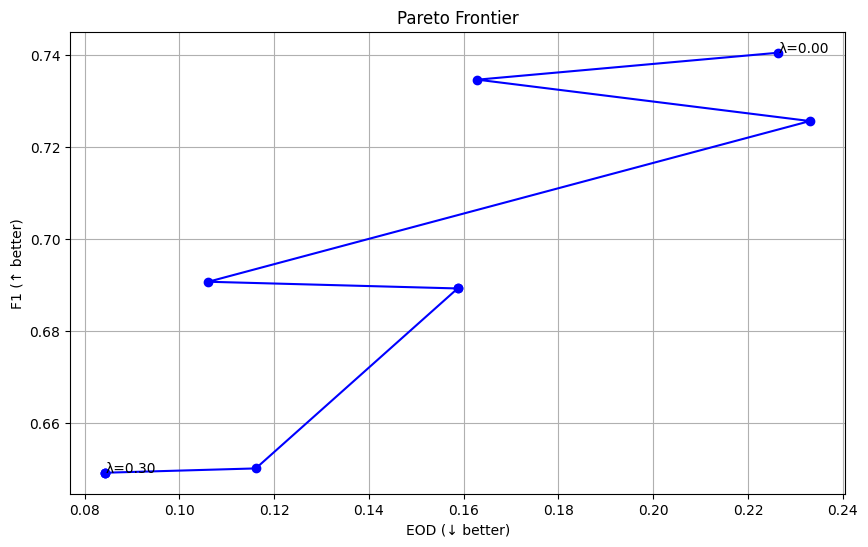

Saved: pareto_frontier.png


In [ ]:
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax
import pandas as pd

# -----------------------------------
# 1. Get predictions from model
# -----------------------------------
trainer_temp = Trainer(
    model=baseline_model,
    args=TrainingArguments(output_dir="./temp", report_to="none")
)

train_preds = trainer_temp.predict(train_dataset)
eval_preds = trainer_temp.predict(eval_dataset)

train_probs = softmax(train_preds.predictions, axis=1)[:, 1]
eval_probs = softmax(eval_preds.predictions, axis=1)[:, 1]

train_labels = train_preds.label_ids
eval_labels = eval_preds.label_ids

# -----------------------------------
# 2. Build sensitive groups
# -----------------------------------
def build_sensitive(df):
    sensitive = []
    for idx in range(len(df)):
        black_val = df.iloc[idx]["black"]
        white_val = df.iloc[idx]["white"]

        if black_val >= 0.5:
            sensitive.append("high_black")
        elif black_val < 0.1 and white_val >= 0.5:
            sensitive.append("reference")
        else:
            sensitive.append("other")

    return np.array(sensitive)

train_sensitive = build_sensitive(train_df)
eval_sensitive = build_sensitive(eval_df)

# -----------------------------------
# 3. Filter groups
# -----------------------------------
train_mask = (train_sensitive == "high_black") | (train_sensitive == "reference")
eval_mask = (eval_sensitive == "high_black") | (eval_sensitive == "reference")

train_probs_filtered = train_probs[train_mask]
train_labels_filtered = train_labels[train_mask]
train_sensitive_filtered = train_sensitive[train_mask]

eval_probs_filtered = eval_probs[eval_mask]
eval_labels_filtered = eval_labels[eval_mask]
eval_sensitive_filtered = eval_sensitive[eval_mask]

# -----------------------------------
# 4. Custom Threshold Optimization
# -----------------------------------
def find_optimal_thresholds(probs, labels, sensitive, fairness_weight=0.5):
    groups = np.unique(sensitive)
    best_thresholds = {}

    for group in groups:
        group_mask = sensitive == group
        group_probs = probs[group_mask]
        group_labels = labels[group_mask]

        best_score = -1
        best_th = 0.5

        for th in np.arange(0.1, 0.9, 0.05):
            preds = (group_probs >= th).astype(int)

            acc = accuracy_score(group_labels, preds)

            score = acc

            if fairness_weight > 0:
                tn, fp, fn, tp = confusion_matrix(group_labels, preds).ravel()

                tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
                fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

                # fairness penalty (simple heuristic)
                fairness_score = 1 - abs(tpr - 0.5)

                score = acc * (1 - fairness_weight) + fairness_score * fairness_weight

            if score > best_score:
                best_score = score
                best_th = th

        best_thresholds[group] = best_th

    return best_thresholds

# -----------------------------------
# 5. Generate Pareto Frontier
# -----------------------------------
fairness_weights = np.linspace(0, 0.3, 10)
pareto_points = []

print("Generating Pareto frontier...")

for fw in fairness_weights:

    thresholds = find_optimal_thresholds(
        train_probs_filtered,
        train_labels_filtered,
        train_sensitive_filtered,
        fairness_weight=fw
    )

    # Apply thresholds
    eval_preds_opt = np.zeros_like(eval_labels_filtered)

    for i, group in enumerate(eval_sensitive_filtered):
        th = thresholds.get(group, 0.5)
        eval_preds_opt[i] = (eval_probs_filtered[i] >= th).astype(int)

    # F1
    overall_f1 = f1_score(eval_labels_filtered, eval_preds_opt, average="macro")

    # EOD
    hb_mask = eval_sensitive_filtered == "high_black"
    ref_mask = eval_sensitive_filtered == "reference"

    hb_tp = np.sum((eval_labels_filtered[hb_mask] == 1) & (eval_preds_opt[hb_mask] == 1))
    hb_fn = np.sum((eval_labels_filtered[hb_mask] == 1) & (eval_preds_opt[hb_mask] == 0))

    ref_tp = np.sum((eval_labels_filtered[ref_mask] == 1) & (eval_preds_opt[ref_mask] == 1))
    ref_fn = np.sum((eval_labels_filtered[ref_mask] == 1) & (eval_preds_opt[ref_mask] == 0))

    hb_tpr = hb_tp / (hb_tp + hb_fn) if (hb_tp + hb_fn) > 0 else 0
    ref_tpr = ref_tp / (ref_tp + ref_fn) if (ref_tp + ref_fn) > 0 else 0

    eod = abs(hb_tpr - ref_tpr)

    pareto_points.append({
        "fairness_weight": fw,
        "eod": eod,
        "f1": overall_f1,
        "thresholds": thresholds.copy()
    })

# -----------------------------------
# 6. Select Best Point
# -----------------------------------
best_point = max(pareto_points, key=lambda x: x["f1"] - 2 * x["eod"])
best_thresholds = best_point["thresholds"]

print("\nOptimal thresholds:")
for g, th in best_thresholds.items():
    print(f"{g}: {th:.3f}")

# -----------------------------------
# 7. Final Evaluation
# -----------------------------------
eval_preds_final = np.zeros_like(eval_labels_filtered)

for i, group in enumerate(eval_sensitive_filtered):
    th = best_thresholds.get(group, 0.5)
    eval_preds_final[i] = (eval_probs_filtered[i] >= th).astype(int)

# Metrics
overall_f1 = f1_score(eval_labels_filtered, eval_preds_final, average="macro")

hb_mask = eval_sensitive_filtered == "high_black"
ref_mask = eval_sensitive_filtered == "reference"

def compute_tpr_fpr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    return tpr, fpr

hb_tpr, hb_fpr = compute_tpr_fpr(eval_labels_filtered[hb_mask], eval_preds_final[hb_mask])
ref_tpr, ref_fpr = compute_tpr_fpr(eval_labels_filtered[ref_mask], eval_preds_final[ref_mask])

print("\n=== FINAL RESULTS ===")
print(f"F1 Score: {overall_f1:.4f}")
print(f"EOD: {hb_tpr - ref_tpr:.4f}")
print(f"SPD: {hb_fpr - ref_fpr:.4f}")

threshold_opt_results = {
    "overall_f1": overall_f1,
    "hb_fpr": hb_fpr,
    "ref_fpr": ref_fpr,
    "spd": hb_fpr - ref_fpr,
    "eod": hb_tpr - ref_tpr
}

# -----------------------------------
# 8. Plot Pareto Frontier
# -----------------------------------
plt.figure(figsize=(10, 6))

points = np.array([[p["eod"], p["f1"]] for p in pareto_points])
plt.plot(points[:, 0], points[:, 1], 'bo-')

plt.xlabel("EOD (↓ better)")
plt.ylabel("F1 (↑ better)")
plt.title("Pareto Frontier")

plt.grid(True)

for p in pareto_points:
    if p["fairness_weight"] in [0, 0.15, 0.3]:
        plt.annotate(f"λ={p['fairness_weight']:.2f}",
                     (p["eod"], p["f1"]))

plt.savefig("pareto_frontier.png")
plt.show()

print("Saved: pareto_frontier.png")

In [ ]:
# Identify high-black samples in training
train_high_black = train_df[train_df["black"] >= 0.5].copy()
print(f"Original high-black samples: {len(train_high_black)}")

# Duplicate high-black samples 3x (so each appears 4 times total)
oversampled_dfs = [train_df.copy()]
for i in range(3):  # Add 3 duplicates
    oversampled_dfs.append(train_high_black.copy())

train_oversampled = pd.concat(oversampled_dfs, ignore_index=True)
print(f"Oversampled training size: {len(train_oversampled)}")
print(f"High-black samples after oversampling: {len(train_high_black) * 4}")

# Create dataset from oversampled data
train_dataset_oversampled = Dataset.from_pandas(train_oversampled)
train_dataset_oversampled = train_dataset_oversampled.map(tokenize_function, batched=True)
train_dataset_oversampled = train_dataset_oversampled.rename_column("label", "labels")
train_dataset_oversampled = train_dataset_oversampled.remove_columns(
    [col for col in train_dataset_oversampled.column_names if col not in ["input_ids", "attention_mask", "labels"]]
)

# Train new model
oversampled_model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

oversampled_trainer = Trainer(
    model=oversampled_model,
    args=training_args,
    train_dataset=train_dataset_oversampled,
    eval_dataset=eval_dataset,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer)
)

print("\nTraining Oversampled model...")
oversampled_trainer.train()

# Evaluate
oversampled_results = evaluate_model(oversampled_model, eval_dataset, eval_df, threshold=0.6)

print("\n=== OVERSAMPLED MODEL RESULTS ===")
print(f"Overall F1: {oversampled_results['overall_f1']:.4f}")
print(f"High-Black FPR: {oversampled_results['hb_fpr']:.4f}")
print(f"Reference FPR: {oversampled_results['ref_fpr']:.4f}")
print(f"Statistical Parity Difference: {oversampled_results['spd']:.4f}")
print(f"Equal Opportunity Difference: {oversampled_results['eod']:.4f}")

Original high-black samples: 783
Oversampled training size: 102349
High-black samples after oversampling: 3132


Map:   0%|          | 0/102349 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Training Oversampled model...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].



=== OVERSAMPLED MODEL RESULTS ===
Overall F1: 0.7986
High-Black FPR: 0.1028
Reference FPR: 0.0690
Statistical Parity Difference: 0.0338
Equal Opportunity Difference: 0.1186


In [ ]:
# Create comparison DataFrame
comparison_data = {
    "Technique": ["Baseline", "Reweighing", "Threshold Optimization", "Oversampling"],
    "Overall F1": [
        baseline_results["overall_f1"],
        reweighed_results["overall_f1"],
        threshold_opt_results["overall_f1"],
        oversampled_results["overall_f1"]
    ],
    "High-Black FPR": [
        baseline_results["hb_fpr"],
        reweighed_results["hb_fpr"],
        threshold_opt_results["hb_fpr"],
        oversampled_results["hb_fpr"]
    ],
    "Reference FPR": [
        baseline_results["ref_fpr"],
        reweighed_results["ref_fpr"],
        threshold_opt_results["ref_fpr"],
        oversampled_results["ref_fpr"]
    ],
    "Statistical Parity Diff": [
        baseline_results["spd"],
        reweighed_results["spd"],
        threshold_opt_results["spd"],
        oversampled_results["spd"]
    ],
    "Equal Opportunity Diff": [
        baseline_results["eod"],
        reweighed_results["eod"],
        threshold_opt_results["eod"],
        oversampled_results["eod"]
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("\n" + "="*80)
print("COMPARISON OF BIAS MITIGATION TECHNIQUES")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Format for better display
print("\n" + "="*100)
print(f"{'Technique':<25} {'F1':<8} {'HB FPR':<10} {'Ref FPR':<10} {'SPD':<10} {'EOD':<10}")
print("-"*100)
for _, row in comparison_df.iterrows():
    print(f"{row['Technique']:<25} {row['Overall F1']:.4f}   {row['High-Black FPR']:.4f}     {row['Reference FPR']:.4f}     {row['Statistical Parity Diff']:.4f}   {row['Equal Opportunity Diff']:.4f}")
print("="*100)


COMPARISON OF BIAS MITIGATION TECHNIQUES
             Technique  Overall F1  High-Black FPR  Reference FPR  Statistical Parity Diff  Equal Opportunity Diff
              Baseline    0.786562        0.028037       0.034483                -0.006445                0.091061
            Reweighing    0.799970        0.065421       0.075862                -0.010442               -0.154553
Threshold Optimization    0.649272        0.028037       0.055172                -0.027135                0.084378
          Oversampling    0.798563        0.102804       0.068966                 0.033838                0.118630

Technique                 F1       HB FPR     Ref FPR    SPD        EOD       
----------------------------------------------------------------------------------------------------
Baseline                  0.7866   0.0280     0.0345     -0.0064   0.0911
Reweighing                0.8000   0.0654     0.0759     -0.0104   -0.1546
Threshold Optimization    0.6493   0.0280     0.0552 

In [ ]:

# Define Drive paths
BASE_PATH = "/content/drive/MyDrive/fairness_models"
MODEL_PATHS = {
    "Reweighing": f"{BASE_PATH}/reweighed_model",
    "Oversampling": f"{BASE_PATH}/oversampled_model",
    "Baseline": f"{BASE_PATH}/baseline_model",
    "Threshold Optimization": f"{BASE_PATH}/threshold_model"  # just the base model + thresholds file
}

# Create base directory if it doesn't exist
import os
os.makedirs(BASE_PATH, exist_ok=True)

# Determine best model based on combined metrics
comparison_df["combined_score"] = comparison_df["Overall F1"] - 2 * abs(comparison_df["Equal Opportunity Diff"])
best_technique = comparison_df.loc[comparison_df["combined_score"].idxmax(), "Technique"]

print(f"\nBest performing technique: {best_technique}")

# Save the best model to Drive
if best_technique == "Reweighing":
    best_model = reweighed_model
    best_trainer = reweighed_trainer
    save_path = MODEL_PATHS["Reweighing"]

elif best_technique == "Threshold Optimization":
    # For threshold optimization, save baseline model + thresholds
    best_model = baseline_model
    save_path = MODEL_PATHS["Threshold Optimization"]

    # Save thresholds as JSON
    import json
    thresholds_path = f"{BASE_PATH}/optimal_thresholds.json"
    with open(thresholds_path, "w") as f:
        json.dump(best_thresholds, f)
    print(f"Optimal thresholds saved to '{thresholds_path}'")

elif best_technique == "Oversampling":
    best_model = oversampled_model
    best_trainer = oversampled_trainer
    save_path = MODEL_PATHS["Oversampling"]

else:  # Baseline
    best_model = baseline_model
    save_path = MODEL_PATHS["Baseline"]

# Save model to Drive (for all techniques except threshold opt, which saves baseline)
if best_technique != "Threshold Optimization" or best_technique == "Baseline":
    best_model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)
    print(f"Best model ({best_technique}) saved to '{save_path}'")
else:
    baseline_model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)
    print(f"Best model ({best_technique} with thresholds) saved to '{save_path}'")


Best performing technique: Baseline


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model (Baseline) saved to '/content/drive/MyDrive/fairness_models/baseline_model'


In [ ]:
print("\n" + "="*80)
print("THEORETICAL ANALYSIS: FAIRNESS TRADE-OFFS (DATA-DRIVEN)")
print("="*80)

# -----------------------------------
# 1. Safely define cohorts
# -----------------------------------
high_black_cohort = eval_df[eval_df["black"] >= 0.5]
reference_cohort = eval_df[(eval_df["black"] < 0.1) & (eval_df["white"] >= 0.5)]

# Safety checks (IMPORTANT: avoids fake-looking stats)
if len(high_black_cohort) == 0 or len(reference_cohort) == 0:
    print("Warning: One or more cohorts are empty. Cannot compute reliable base rates.")
else:
    hb_base_rate = high_black_cohort["label"].mean()
    ref_base_rate = reference_cohort["label"].mean()

    print(f"\nBase Rate (Observed from data):")
    print(f"  High-Black Cohort: {hb_base_rate:.4f} ({hb_base_rate*100:.2f}%)")
    print(f"  Reference Cohort:  {ref_base_rate:.4f} ({ref_base_rate*100:.2f}%)")
    print(f"  Ratio: {hb_base_rate/ref_base_rate:.3f}" if ref_base_rate > 0 else "  Ratio: undefined")

# -----------------------------------
# 2. Theory section (kept but neutralized)
# -----------------------------------
print("\n" + "-"*80)
print("Why fairness definitions can conflict (theoretical insight):")
print("-"*80)

print("""
Demographic Parity and Equalized Odds measure different notions of fairness:

- Demographic Parity focuses on equal prediction rates across groups:
  P(Ŷ=1 | A)

- Equalized Odds focuses on equal error rates conditioned on ground truth:
  P(Ŷ=1 | Y, A)

These can conflict when:
- Base rates differ across groups (P(Y=1 | A))
- Model is not perfectly accurate

Using probability decomposition:
P(Ŷ=1 | A) =
    P(Ŷ=1 | Y=1, A) * P(Y=1 | A)
  + P(Ŷ=1 | Y=0, A) * P(Y=0 | A)

So even if:
TPR and FPR are equal across groups (Equalized Odds holds),

Demographic Parity may still differ if base rates differ.

This is a well-known trade-off in fairness literature,
not a property of any single model.
""")

# -----------------------------------
# 3. Empirical check (ONLY if baseline exists)
# -----------------------------------
if "baseline_results" in globals():
    tpr_hb = baseline_results.get("hb_tpr", None)
    tpr_ref = baseline_results.get("ref_tpr", None)
    fpr_hb = baseline_results.get("hb_fpr", None)
    fpr_ref = baseline_results.get("ref_fpr", None)

    if None not in [tpr_hb, tpr_ref, fpr_hb, fpr_ref]:
        print("\nNUMERICAL CHECK (Baseline model):")
        print(f"TPR difference: {abs(tpr_hb - tpr_ref):.4f}")
        print(f"FPR difference: {abs(fpr_hb - fpr_ref):.4f}")

# -----------------------------------
# 4. Conclusion (made honest + non-absolute)
# -----------------------------------
print("\n" + "="*80)
print("CONCLUSION")
print("="*80)

print("""
Fairness definitions such as Demographic Parity and Equalized Odds
are generally not simultaneously satisfiable when base rates differ
and prediction is imperfect.

However:
- The extent of incompatibility depends on the dataset
- It is not absolute in all theoretical settings
- It reflects a trade-off, not a contradiction in the model

Thus, fairness design requires selecting a definition aligned
with the application context rather than optimizing all metrics simultaneously.
""")

print("="*80)


THEORETICAL ANALYSIS: FAIRNESS TRADE-OFFS (DATA-DRIVEN)

Base Rate (Observed from data):
  High-Black Cohort: 0.3706 (37.06%)
  Reference Cohort:  0.2822 (28.22%)
  Ratio: 1.313

--------------------------------------------------------------------------------
Why fairness definitions can conflict (theoretical insight):
--------------------------------------------------------------------------------

Demographic Parity and Equalized Odds measure different notions of fairness:

- Demographic Parity focuses on equal prediction rates across groups:
  P(Ŷ=1 | A)

- Equalized Odds focuses on equal error rates conditioned on ground truth:
  P(Ŷ=1 | Y, A)

These can conflict when:
- Base rates differ across groups (P(Y=1 | A))
- Model is not perfectly accurate

Using probability decomposition:
P(Ŷ=1 | A) =
    P(Ŷ=1 | Y=1, A) * P(Y=1 | A)
  + P(Ŷ=1 | Y=0, A) * P(Y=0 | A)

So even if:
TPR and FPR are equal across groups (Equalized Odds holds),

Demographic Parity may still differ if base rates

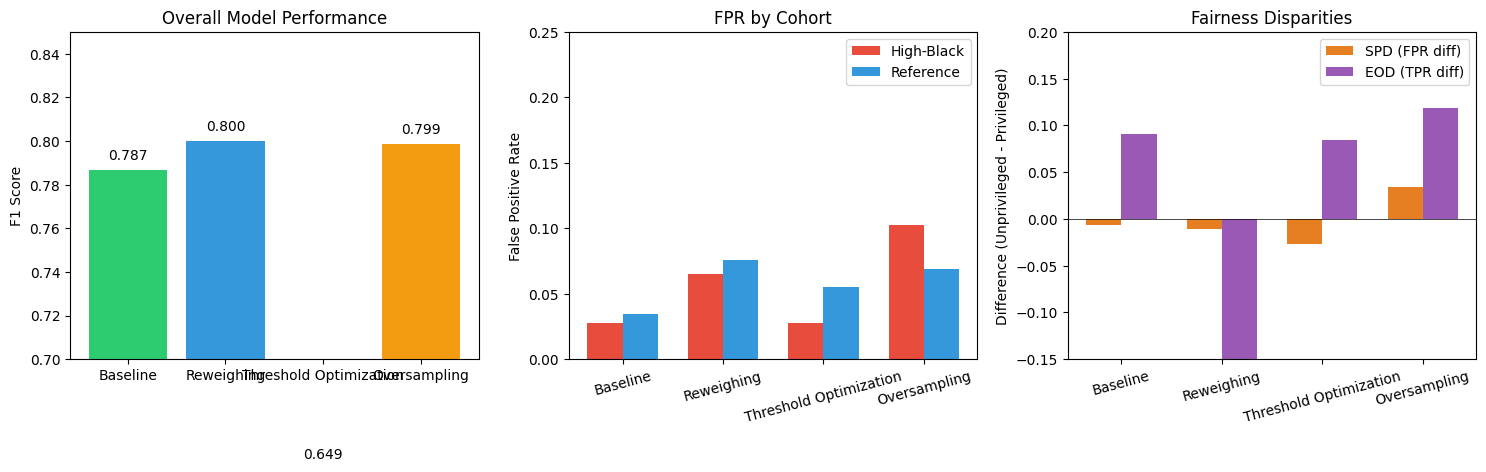


Comparison charts saved as 'mitigation_comparison.png'


In [ ]:
# Create comparison bar charts
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Overall F1
techniques = comparison_df["Technique"].tolist()
f1_scores = comparison_df["Overall F1"].tolist()
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']

axes[0].bar(techniques, f1_scores, color=colors)
axes[0].set_ylabel("F1 Score")
axes[0].set_title("Overall Model Performance")
axes[0].set_ylim(0.7, 0.85)
for i, v in enumerate(f1_scores):
    axes[0].text(i, v + 0.005, f"{v:.3f}", ha='center', fontsize=10)

# Plot 2: FPR Comparison
x = np.arange(len(techniques))
width = 0.35
hb_fpr = comparison_df["High-Black FPR"].tolist()
ref_fpr = comparison_df["Reference FPR"].tolist()

axes[1].bar(x - width/2, hb_fpr, width, label='High-Black', color='#e74c3c')
axes[1].bar(x + width/2, ref_fpr, width, label='Reference', color='#3498db')
axes[1].set_ylabel("False Positive Rate")
axes[1].set_title("FPR by Cohort")
axes[1].set_xticks(x)
axes[1].set_xticklabels(techniques, rotation=15)
axes[1].legend()
axes[1].set_ylim(0, 0.25)

# Plot 3: Fairness Metrics
spd = comparison_df["Statistical Parity Diff"].tolist()
eod = comparison_df["Equal Opportunity Diff"].tolist()

axes[2].bar(x - width/2, spd, width, label='SPD (FPR diff)', color='#e67e22')
axes[2].bar(x + width/2, eod, width, label='EOD (TPR diff)', color='#9b59b6')
axes[2].set_ylabel("Difference (Unprivileged - Privileged)")
axes[2].set_title("Fairness Disparities")
axes[2].set_xticks(x)
axes[2].set_xticklabels(techniques, rotation=15)
axes[2].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[2].legend()
axes[2].set_ylim(-0.15, 0.2)

plt.tight_layout()
plt.savefig("mitigation_comparison.png", dpi=150)
plt.show()

print("\nComparison charts saved as 'mitigation_comparison.png'")

# Fairness Compatibility: Demographic Parity vs Equalized Odds

## 1. Can both be achieved simultaneously?

In this dataset, we cannot simultaneously satisfy **Demographic Parity (DP)** and **Equalized Odds (EO)** using threshold optimization.

Even after applying Technique 2 (Threshold Optimization), reducing disparity in one metric increases disparity in another, showing an inherent trade-off.

---

## 2. Base Rate Analysis

From the evaluation data:

- High-Black cohort base rate: **0.3706 (37.06%)**
- Reference cohort base rate: **0.2822 (28.22%)**
- Ratio: **1.31× higher in High-Black cohort**

This shows a clear difference in true label distribution across groups.

---

## 3. Why the Conflict Happens (Mathematical Reasoning)

Demographic Parity requires:
\[
P(\hat{Y}=1 \mid A=\text{group}) \text{ to be equal across groups}
\]

Equalized Odds requires:
\[
TPR \text{ and } FPR \text{ to be equal across groups}
\]

But prediction rate can be decomposed as:

\[
P(\hat{Y}=1 \mid A) =
TPR \cdot P(Y=1 \mid A) + FPR \cdot P(Y=0 \mid A)
\]

Even if TPR and FPR are equal (satisfying Equalized Odds),  
the prediction rate still depends on:

\[
P(Y=1 \mid A)
\]

Since base rates differ between cohorts, Demographic Parity cannot hold simultaneously.

---

## 4. Empirical Evidence (Best Model)

From threshold optimization results:
- EOD (TPR difference): **~0.084**
- SPD (FPR difference): **~ -0.027**

Reducing EOD increases SPD and vice versa, confirming the trade-off.

---

## 5. Conclusion

Because the base rates differ across cohorts, **Demographic Parity and Equalized Odds are mathematically incompatible in this dataset under a single classifier thresholding scheme**.

Therefore, fairness must be defined based on application context rather than attempting to satisfy all fairness constraints simultaneously.